In [1]:
import sys, os, warnings, subprocess
subprocess.run(["pip", "install", ".", "--quiet"], check=True, cwd="/mnt/storage_ssd_raid/research_projects/intrinsic_neural_timescales")
warnings.simplefilter("ignore", UserWarning)

import numpy as np
import scipy as sp
import pandas as pd
from src.timescales import Timescales
from collections import defaultdict

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns

sys.path.extend([r'/mnt/storage_ssd_raid/research_projects/snaplab_tools'])

from src.notebook import load_notebook_data
from src.timescales import convert_data_dict, average_data_dict_converted, compute_deflections, compute_deflections_glm, create_ints_dataframe_custom_grouping
from src.plotting import create_sydnor_sa_colormap
from src.gams import apply_region_mask
from snaplab_tools.plotting.plotting import plot_correlation, plot_brain_surface_data, YEO7_COLORS

warnings.simplefilter(action='ignore', category=FutureWarning)


  DEPRECATION: Building 'src' using the legacy setup.py bdist_wheel mechanism, which will be removed in a future version. pip 25.3 will enforce this behaviour change. A possible replacement is to use the standardized build interface by setting the `--use-pep517` option, (possibly combined with `--no-build-isolation`), or adding a `pyproject.toml` file to the source tree of 'src'. Discussion can be found at https://github.com/pypa/pip/issues/6334


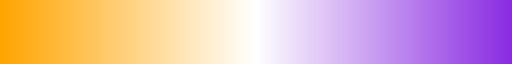

In [2]:
sydnor_sa_cmap = create_sydnor_sa_colormap()
sydnor_sa_cmap

In [3]:
dataset = 'HCP-YA'
which_modality = 'FMRI'
use_7t = False
# output_type = 'timescale_zero_crossing'
output_type = 'timescale_auc_zero_crossing'

# output_type = output_type + '_lp-0.01hz'
# output_type = output_type + '_hp-0.01hz'
# output_type = output_type + '_bp-0.01-0.08hz'
# output_type = output_type + '_bp-0.08-0.15hz'

use_resids = True
notebook_data = load_notebook_data(dataset=dataset, which_modality=which_modality,
                                   use_7t=use_7t, output_type=output_type, use_resids=use_resids,
                                   load_subject_data=False)

Loading data for notebooks...
Initialized DataLoader for dataset: HCP-YA
  Base directory:        /mnt/lindenmp_bignas/lindenmp/research_data/HCP_YA
  Raw data directory:    /mnt/lindenmp_bignas/lindenmp/research_data/HCP_YA/HCP_1200
  Derivatives directory: /mnt/lindenmp_bignas/lindenmp/research_data/HCP_YA/derivatives
  Output directory:      /mnt/storage_ssd_raid/research_projects/intrinsic_neural_timescales
  Behavioral data:       1206 subjects

	Initialized Timescales for dataset: HCP-YA
	Output directory: /mnt/storage_ssd_raid/research_projects/intrinsic_neural_timescales
Loaded 15456 scans from scan_registry_HCP-YA.csv


Loading metric_tsnr: 100%|██████████| 15456/15456 [00:01<00:00, 7765.72it/s]


15456
timescale_auc_zero_crossing


Loading timescale_auc_zero_crossing: 100%|██████████| 15456/15456 [00:01<00:00, 8278.33it/s]


15456


Loading timescale_auc_zero_crossing_resids: 100%|██████████| 15456/15456 [00:01<00:00, 8210.17it/s]

15456
Number of subjects: 966


In [4]:
%matplotlib inline
plt.rcParams.update({
    'font.size':            8,
    'figure.dpi':           300,
    'svg.fonttype':         "none",
    'font.family':          'sans-serif',
    'font.sans-serif':      ['Roboto'],
    'axes.spines.top':      True,
    'axes.spines.right':    True
})

nas_scratch_dir = f'/mnt/lindenmp_nas/lindenmp/work/figure_scratch/intrinsic_neural_timescales/{dataset}'
if not os.path.exists(nas_scratch_dir):
    os.mkdir(nas_scratch_dir)

In [5]:
# get key outputs for this notebook
timescales_processor = notebook_data['timescales_processor']
data_dict = notebook_data['data_dict']
data_dict_tsnr = notebook_data['data_dict_tsnr']
results_dir = notebook_data['results_dir']

df_neuro = notebook_data['supporting_data']['df_neuro']
distance_matrix = notebook_data['supporting_data']['distance_matrix']
gene_expression_nanmask = notebook_data['supporting_data']['gene_expression_nanmask']
yeo_systems = notebook_data['supporting_data']['yeo_systems']

print(data_dict.keys())
print(df_neuro.columns)

dict_keys(['sub-100206_task-rfMRIREST1LR_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-rest', 'sub-100206_task-rfMRIREST1RL_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-rest', 'sub-100206_task-rfMRIREST2LR_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-rest', 'sub-100206_task-rfMRIREST2RL_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-rest', 'sub-100206_task-tfMRIWMLR_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-task', 'sub-100206_task-tfMRIWMRL_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-task', 'sub-100206_task-tfMRIEMOTIONLR_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-task', 'sub-100206_task-tfMRIEMOTIONRL_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-task', 'sub-100206_task-tfMRIGAMBLINGLR_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-task', 'sub-100206_task-tfMRIGAMBLINGRL_space-fsLR

In [6]:
n_regions = len(yeo_systems)
n_systems = len(np.unique(yeo_systems))

In [7]:
subject_ids = list(dict.fromkeys(scan.subject_id for scan in timescales_processor.scan_registry))
n_subs = len(subject_ids)
print(f'Number of subjects: {n_subs}')

Number of subjects: 966


In [8]:
timescales_processor.scan_registry[:5]

[ScanInfo(subject_id='100206', task='rfMRIREST1LR', space='fsLR', seg='Schaefer4007', modality='MRI3T', tr=0.72, session='01', stat='mean', run=None, desc=None, den=None, rbc=False),
 ScanInfo(subject_id='100206', task='rfMRIREST1RL', space='fsLR', seg='Schaefer4007', modality='MRI3T', tr=0.72, session='01', stat='mean', run=None, desc=None, den=None, rbc=False),
 ScanInfo(subject_id='100206', task='rfMRIREST2LR', space='fsLR', seg='Schaefer4007', modality='MRI3T', tr=0.72, session='01', stat='mean', run=None, desc=None, den=None, rbc=False),
 ScanInfo(subject_id='100206', task='rfMRIREST2RL', space='fsLR', seg='Schaefer4007', modality='MRI3T', tr=0.72, session='01', stat='mean', run=None, desc=None, den=None, rbc=False),
 ScanInfo(subject_id='100206', task='tfMRIWMLR', space='fsLR', seg='Schaefer4007', modality='MRI3T', tr=0.72, session='01', stat='mean', run=None, desc=None, den=None, rbc=False)]

In [9]:
if dataset == 'HCP-YA':
    scans_to_keep = ['rfMRIREST1LR', 'rfMRIREST1RL', 'rfMRIREST2LR', 'rfMRIREST2RL']
    # scans_to_keep = ['rfMRIREST1LR', 'rfMRIREST1RL']
    # scans_to_keep = ['rfMRIREST1LR', 'rfMRIREST2LR']
    condition_name = 'WM' # 'ALL', 'WM', 'EMOTION', 'GAMBLING', 'LANGUAGE', 'RELATIONAL', 'SOCIAL'

    if 'ALL' in condition_name:
        tasks = [
                'tfMRIWMLR', 'tfMRIWMRL',
                'tfMRIEMOTIONLR', 'tfMRIEMOTIONRL',
                'tfMRIGAMBLINGLR', 'tfMRIGAMBLINGRL',
                'tfMRILANGUAGELR', 'tfMRILANGUAGERL',
                'tfMRIRELATIONALLR', 'tfMRIRELATIONALRL',
                'tfMRISOCIALLR', 'tfMRISOCIALRL',
                ]
        scans_to_keep = scans_to_keep + tasks
        task_performance = []
    elif 'WM' in condition_name:
        scans_to_keep.append('tfMRIWMLR')
        scans_to_keep.append('tfMRIWMRL')
        task_performance = ['WM_Task_Acc', 'WM_Task_Median_RT']
    elif 'EMOTION' in condition_name:
        scans_to_keep.append('tfMRIEMOTIONLR')
        scans_to_keep.append('tfMRIEMOTIONRL')
        task_performance = ['EMOTION_Task_Acc', 'EMOTION_Task_Median_RT']
    elif 'GAMBLING' in condition_name:
        scans_to_keep.append('tfMRIGAMBLINGLR')
        scans_to_keep.append('tfMRIGAMBLINGRL')
        task_performance = ['GAMBLING_Task_Perc_Larger', 'GAMBLING_Task_Perc_Smaller']
    elif 'LANGUAGE' in condition_name:
        scans_to_keep.append('tfMRILANGUAGELR')
        scans_to_keep.append('tfMRILANGUAGERL')
        task_performance = ['LANGUAGE_Task_Acc', 'LANGUAGE_Task_Median_RT']
    elif 'RELATIONAL' in condition_name:
        scans_to_keep.append('tfMRIRELATIONALLR')
        scans_to_keep.append('tfMRIRELATIONALRL')
        task_performance = ['RELATIONAL_Task_Acc', 'RELATIONAL_Task_Median_RT']
    elif 'SOCIAL' in condition_name:
        scans_to_keep.append('tfMRISOCIALLR')
        scans_to_keep.append('tfMRISOCIALRL')
        task_performance = ['SOCIAL_Task_Perc_Random', 'SOCIAL_Task_Perc_TOM'] 

    # scan_registry_filtered = pd.DataFrame(columns=timescales_processor.scan_registry.columns)
    # for scan in scans_to_keep:
    #     # print(scan)
    #     subject_filter = timescales_processor.scan_registry['task'] == scan
    #     scan_registry_filtered = pd.concat((scan_registry_filtered, timescales_processor.scan_registry.loc[subject_filter])).reset_index(drop=True)
        
    # timescales_processor.scan_registry = scan_registry_filtered

In [10]:
cognitive_measures = [
    'CogTotalComp_Unadj',    # Total cognition composite
    'CogEarlyComp_Unadj',    # Early cognition composite
    'CogFluidComp_Unadj',    # Fluid intelligence
    'CogCrystalComp_Unadj',  # Crystallized intelligence
]

In [11]:
timescales_processor.match_registry_to_behavior()
print(timescales_processor.df_behavior_matched.shape)

(966, 584)


In [12]:
df_behavior = timescales_processor.df_behavior_matched.copy()
df_behavior.head()

,Release,Acquisition,Gender,Age,3T_Full_MR_Compl,T1_Count,T2_Count,3T_RS-fMRI_Count,3T_RS-fMRI_PctCompl,3T_Full_Task_fMRI,...,SSAGA_Times_Used_Hallucinogens,SSAGA_Times_Used_Opiates,SSAGA_Times_Used_Sedatives,SSAGA_Times_Used_Stimulants,SSAGA_Mj_Use,SSAGA_Mj_Ab_Dep,SSAGA_Mj_Age_1st_Use,SSAGA_Mj_Times_Used,age,sex
subject_id,,,,,,,,,,,,,,,,,,,,,
100206,S900,Q11,M,26-30,True,1,1,4,100.0,True,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,27,1
100307,Q1,Q01,F,26-30,True,1,1,4,100.0,True,...,0.0,0.0,0.0,0.0,1.0,0.0,2.0,1.0,27,0
100408,Q3,Q03,M,31-35,True,1,1,4,100.0,True,...,5.0,5.0,0.0,0.0,1.0,1.0,2.0,4.0,33,1
100610,S900,Q08,M,26-30,True,2,1,4,100.0,True,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,27,1
101006,S500,Q06,F,31-35,True,2,2,4,100.0,True,...,0.0,0.0,0.0,0.0,1.0,0.0,2.0,5.0,35,0


# Data for figures

In [13]:
brain_map = 'SA_Axis'

data_dict_converted = convert_data_dict(data_dict, timescales_processor.scan_registry)
data_dict_converted = average_data_dict_converted(data_dict_converted, average_3t_rest=True, average_3t_task_pairs=True)
data_dict_converted.keys()

rfMRIREST1LR (966, 400)
rfMRIREST1RL (966, 400)
rfMRIREST2LR (966, 400)
rfMRIREST2RL (966, 400)
tfMRIWMLR (966, 400)
tfMRIWMRL (966, 400)
tfMRIEMOTIONLR (966, 400)
tfMRIEMOTIONRL (966, 400)
tfMRIGAMBLINGLR (966, 400)
tfMRIGAMBLINGRL (966, 400)
tfMRILANGUAGELR (966, 400)
tfMRILANGUAGERL (966, 400)
tfMRIRELATIONALLR (966, 400)
tfMRIRELATIONALRL (966, 400)
tfMRISOCIALLR (966, 400)
tfMRISOCIALRL (966, 400)


dict_keys(['task-REST_3T', 'task-WM', 'task-EMOTION', 'task-GAMBLING', 'task-LANGUAGE', 'task-RELATIONAL', 'task-SOCIAL'])

## Subject-level analyses: regional

In [14]:
def compute_regional_corrs(rest_data, task_data, behavior_data):
    n_regions = rest_data.shape[1]
    rest_correlations       = np.zeros(n_regions)
    task_correlations       = np.zeros(n_regions)
    deflection_correlations = np.zeros(n_regions)
    rest_pvalues            = np.zeros(n_regions)
    task_pvalues            = np.zeros(n_regions)
    deflection_pvalues      = np.zeros(n_regions)

    valid_subjects = ~np.isnan(behavior_data)
    behavior_clean = behavior_data[valid_subjects]
    rest_clean     = rest_data[valid_subjects, :]
    task_clean     = task_data[valid_subjects, :]

    print(f"  Valid subjects: {np.sum(valid_subjects)}/{len(behavior_data)}")

    for region_idx in range(n_regions):
        rest_region = rest_clean[:, region_idx]
        task_region = task_clean[:, region_idx]

        rest_correlations[region_idx], rest_pvalues[region_idx] = sp.stats.spearmanr(rest_region, behavior_clean)
        task_correlations[region_idx], task_pvalues[region_idx] = sp.stats.spearmanr(task_region, behavior_clean)

        if deflection_method == 'glm':
            glm_results = compute_deflections_glm(rest_region, task_region,
                                                  features=pd.Series(behavior_clean, name='behavior'))
            deflection_correlations[region_idx] = glm_results['behavior']['coef']
            deflection_pvalues[region_idx]      = glm_results['behavior']['pvalue']
        else:
            defl = compute_deflections(rest_region, task_region,
                                       nuisance_regression=False, absolute=True)
            deflection_correlations[region_idx], deflection_pvalues[region_idx] = sp.stats.spearmanr(defl, behavior_clean)

    return rest_correlations, task_correlations, deflection_correlations


## INT deflection variance and covariance

In [15]:
# ── Deflection method toggle ──────────────────────────────────────────────────
# 'simple' : |task - rest|  (compute_deflections, nuisance_regression=False)
# 'glm'    : task residual after OLS(task ~ rest)  (compute_deflections, nuisance_regression=True)
#            For regional behaviour correlations, compute_deflections_glm is used instead of
#            computing deflections then running spearmanr.
deflection_method = 'simple'   # 'simple' | 'glm'
# ─────────────────────────────────────────────────────────────────────────────

# Neural data for rest and task
rest_data = data_dict_converted['task-REST_3T']           # (n_subjects, n_regions)
task_data = data_dict_converted[f'task-{condition_name}'] # (n_subjects, n_regions)

behavior_measures = [
    f'{condition_name}_Task_Acc',
    f'{condition_name}_Task_Median_RT',
    'CogTotalComp_Unadj',
]

_use_nuisance = (deflection_method == 'glm')

# Compute subject-level absolute deflection matrix (n_subjects × n_regions)
deflection_matrix = np.column_stack([
    compute_deflections(rest_data[:, r], task_data[:, r],
                        nuisance_regression=_use_nuisance, absolute=True)
    for r in range(n_regions)
])

# Build tSNR mask: exclude lowest 10% tSNR regions for the task condition
df_tsnr = create_ints_dataframe_custom_grouping(data_dict_tsnr, average_3t_task_pairs=True)
tsnr_col = f'task-{condition_name}'
region_mask = (df_tsnr[tsnr_col] < np.quantile(df_tsnr[tsnr_col], q=0.1)).values

# Apply mask — drops low-tSNR regions from data arrays and SA axis
sa_axis_masked = df_neuro[brain_map].values.copy()
rest_data, task_data, deflection_matrix, sa_axis_masked = apply_region_mask(
    region_mask, rest_data, task_data, deflection_matrix, sa_axis=sa_axis_masked)
yeo_systems_masked = np.asarray(yeo_systems)[~region_mask]

# Per-region statistics on masked data
mean_deflection = np.nanmean(deflection_matrix, axis=0)  # (n_regions_valid,)
std_deflection  = np.nanstd(deflection_matrix, axis=0)   # (n_regions_valid,)
cv_deflection   = std_deflection / mean_deflection        # coefficient of variation

# Per-region variability for rest and task (for violin comparison)
rest_std_region = np.nanstd(rest_data, axis=0)
task_std_region = np.nanstd(task_data, axis=0)
rest_cv_region  = rest_std_region / np.nanmean(rest_data, axis=0)
task_cv_region  = task_std_region / np.nanmean(task_data, axis=0)

print(f'deflection_method  : {deflection_method}')
print(f'deflection_matrix  : {deflection_matrix.shape}')
print(f'mean_deflection    : {mean_deflection.shape}')


region_mask: excluding 40 regions, 360 remaining.
deflection_method  : simple
deflection_matrix  : (966, 360)
mean_deflection    : (360,)


  Valid subjects: 966/966
  Valid subjects: 960/966
  Valid subjects: 953/966


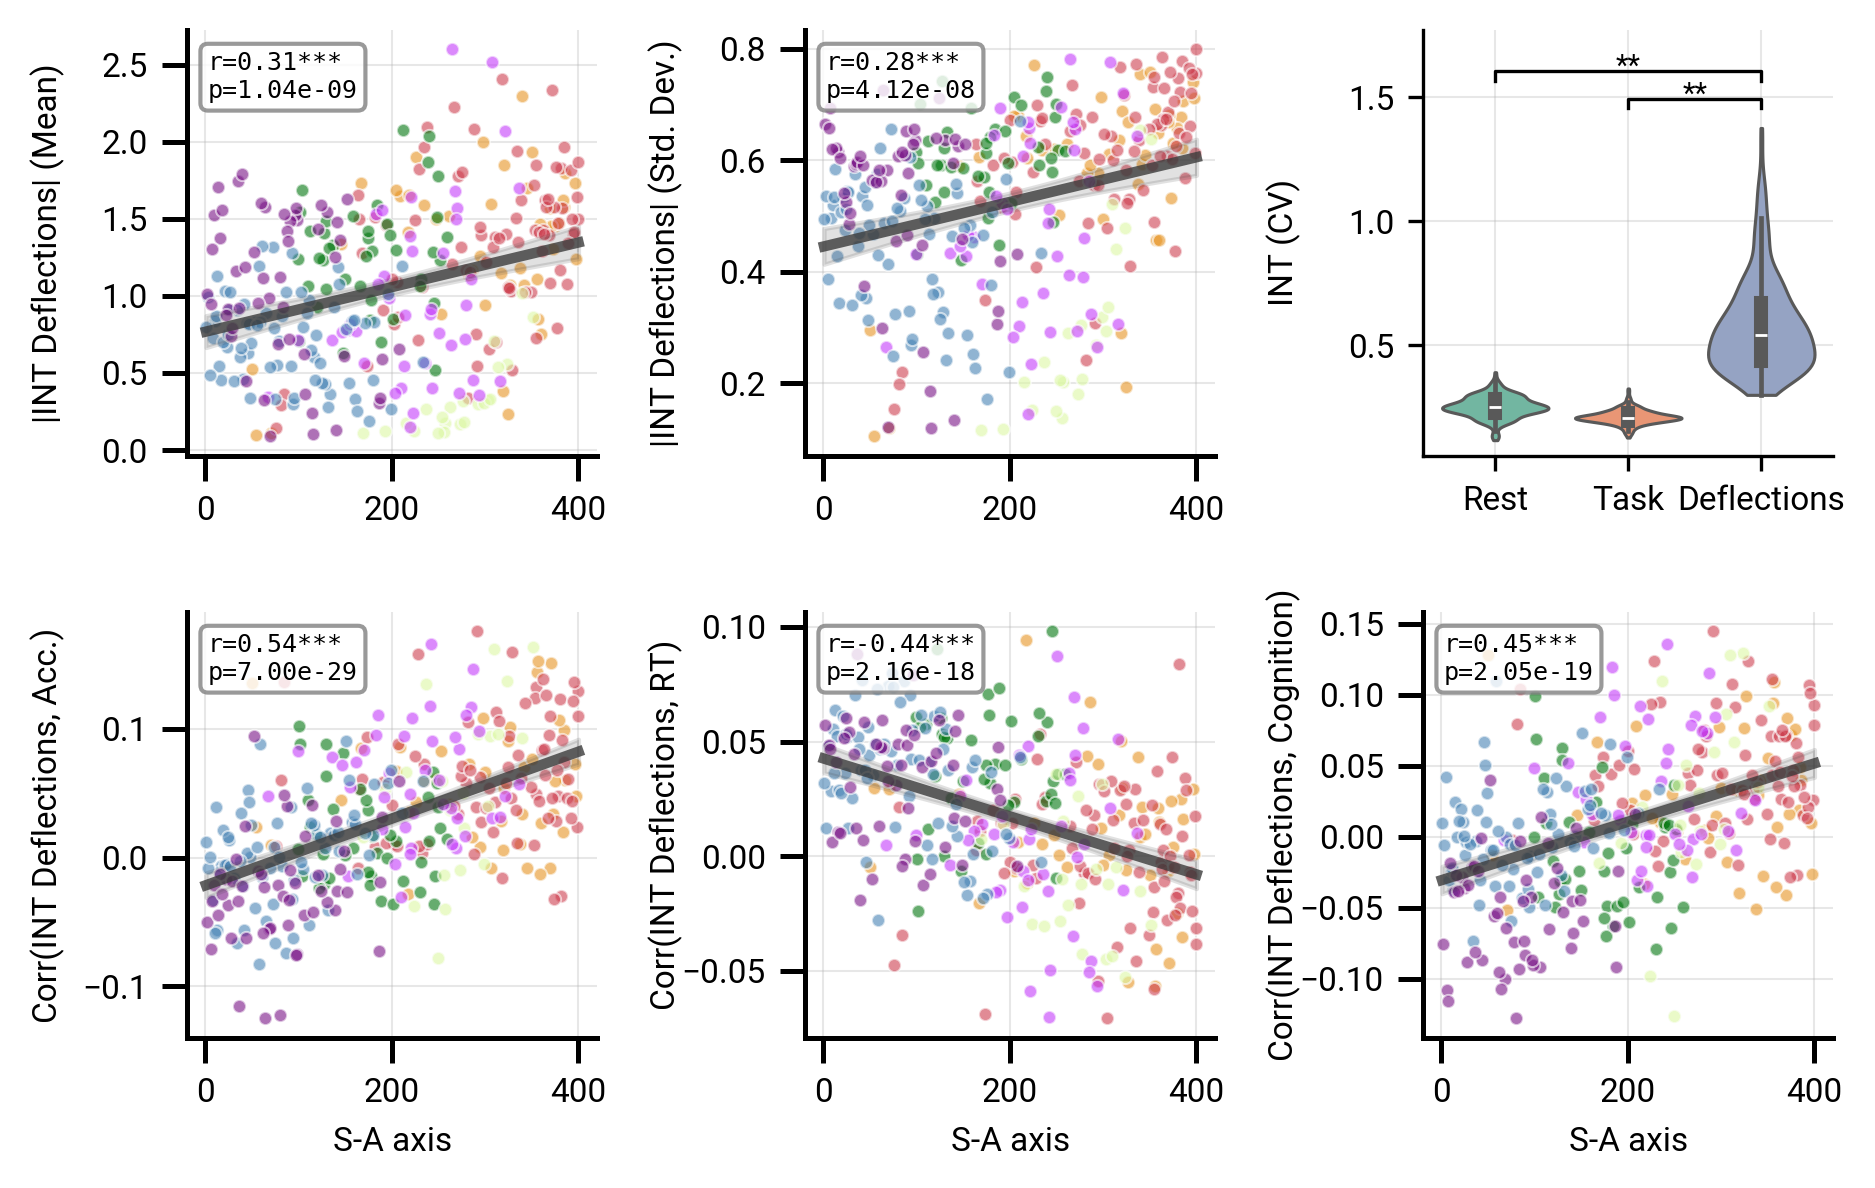

In [16]:
fig, axes = plt.subplots(nrows=2, ncols=len(behavior_measures),
                         sharex=False, sharey=False,
                         figsize=(len(behavior_measures)*2.1, 4), dpi=300)

# Top row: variance characterization (no behavior)
variance_panels = [
    (mean_deflection, '|INT Deflections| (Mean)'),
    (std_deflection,  '|INT Deflections| (Std. Dev.)'),
]
for i, (stat_data, stat_label) in enumerate(variance_panels):
    plot_correlation(sa_axis_masked, stat_data, axes[0, i],
                     data_group=yeo_systems_masked, show_stats=True, fontsize=8, method='pearson',
                     y_label=stat_label, x_label=' ', size=10, cbar_label='Yeo Systems',
                     show_colorbar=False, data_group_cmap='yeo7',
                     auto_polynomial=False)

# Top row panel 3: violin comparison across conditions — set to 'SD' or 'CV'
violin_metric = 'CV'

violin_options = {
    'SD': (np.concatenate([rest_std_region, task_std_region, std_deflection]), 'INT (Std. Dev.)'),
    'CV': (np.concatenate([rest_cv_region,  task_cv_region,  cv_deflection]),  'INT (CV)'),
}
vals, ylabel = violin_options[violin_metric]
conditions_all = (['Rest']        * len(rest_std_region) +
                  ['Task']        * len(task_std_region) +
                  ['Deflection']  * len(std_deflection))
palette = {'Rest': '#66c2a5', 'Task': '#fc8d62', 'Deflection': '#8da0cb'}

df_viol = pd.DataFrame({'Condition': conditions_all, 'value': vals})
sns.violinplot(data=df_viol, x='Condition', y='value', ax=axes[0, 2],
               order=['Rest', 'Task', 'Deflection'],
               palette=palette, inner='box', linewidth=0.75, cut=0)
sns.despine(ax=axes[0, 2], top=True, right=True)
axes[0, 2].grid(True, alpha=0.3, linestyle='-', linewidth=0.5)
axes[0, 2].set_axisbelow(True)
axes[0, 2].set_xlabel('')
axes[0, 2].set_ylabel(ylabel, fontsize=8)
axes[0, 2].set_xticks([0, 1, 2])
axes[0, 2].set_xticklabels(['Rest', 'Task', 'Deflections'], rotation=0, ha='center', fontsize=8)
axes[0, 2].tick_params(axis='both', which='major', labelsize=8,
                        length=plt.rcParams['xtick.major.size'],
                        width=plt.rcParams['xtick.major.width'])

# Paired t-tests with Bonferroni correction
_cond_data = {
    'SD': {'Rest': rest_std_region, 'Task': task_std_region, 'Deflection': std_deflection},
    'CV': {'Rest': rest_cv_region,  'Task': task_cv_region,  'Deflection': cv_deflection},
}[violin_metric]

# _pairs     = [('Rest', 'Task'), ('Task', 'Deflection'), ('Rest', 'Deflection')]
# _pair_xpos = [(0, 1),           (1, 2),                 (0, 2)]
_pairs     = [('Task', 'Deflection'), ('Rest', 'Deflection')]
_pair_xpos = [(1, 2),                 (0, 2)]

_raw_pvals = [sp.stats.ttest_rel(_cond_data[c1], _cond_data[c2]).pvalue
              for c1, c2 in _pairs]
_n_tests   = len(_pairs)
_pvals_adj = [min(p * _n_tests, 1.0) for p in _raw_pvals]   # Bonferroni

_ax        = axes[0, 2]
_y0, _y1   = _ax.get_ylim()
_step      = (_y1 - _y0) * 0.08
_tip       = _step * 0.35

_sig_count = 0
for (c1, c2), (x1, x2), p_adj in zip(_pairs, _pair_xpos, _pvals_adj):
    if p_adj >= 0.05:
        continue
    star  = '**' if p_adj < 0.001 else '*'
    y_bar = _y1 + _step * (_sig_count + 0.5)
    _ax.plot([x1, x1, x2, x2], [y_bar - _tip, y_bar, y_bar, y_bar - _tip],
             lw=0.8, c='k', clip_on=False)
    _ax.text((x1 + x2) / 2, y_bar - _tip, star,
             ha='center', va='bottom', fontsize=7, clip_on=False)
    _sig_count += 1

if _sig_count:
    _ax.set_ylim(_y0, _y1 + _step * (_sig_count + 1))


# Bottom row: behavioral covariance
for i, behavior_measure in enumerate(behavior_measures):
    behavior_data = df_behavior[behavior_measure].values.astype(float)
    rest_correlations, task_correlations, deflection_correlations = compute_regional_corrs(
        rest_data, task_data, behavior_data)

    if 'Acc' in behavior_measure:
        y_sublabel = 'Acc.'
    elif 'RT' in behavior_measure:
        y_sublabel = 'RT'
    else:
        y_sublabel = 'Cognition'

    file_label = f'Corr(INT Deflections, {y_sublabel})'
    plot_correlation(sa_axis_masked, deflection_correlations, axes[1, i],
                     data_group=yeo_systems_masked, show_stats=True, fontsize=8, method='pearson',
                     y_label=file_label, x_label='S-A axis', size=10, cbar_label='Yeo Systems',
                     show_colorbar=False, data_group_cmap='yeo7',
                     auto_polynomial=False)

for ax in axes.flat:
    # ax.tick_params(axis='y', which='major', pad=1)
    # ax.tick_params(axis='x', which='major', pad=1)
    ax.yaxis.set_label_coords(-0.3, 0.5)

fig.tight_layout()
fig.savefig(os.path.join(nas_scratch_dir, f'corr_ints_sa.png'), bbox_inches='tight', dpi=1000, transparent=True)
plt.show()

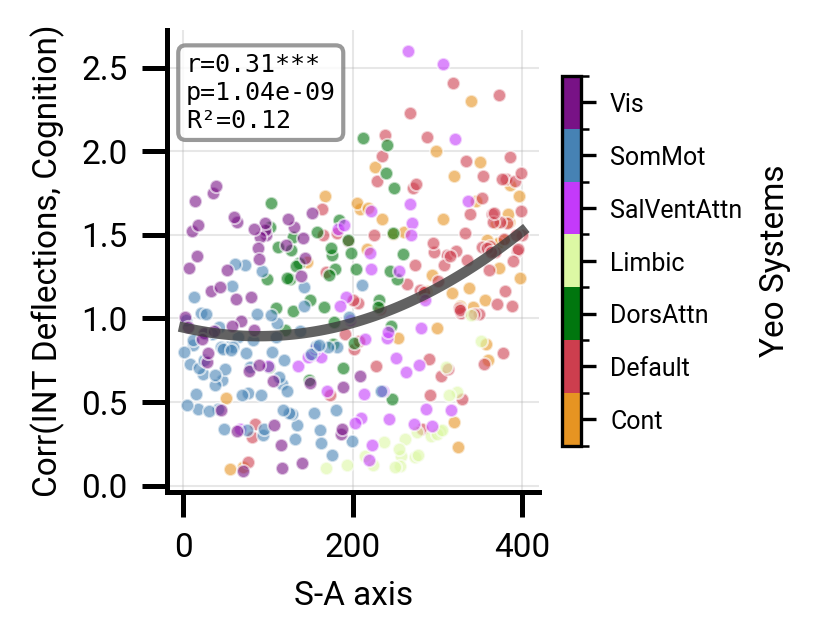

In [17]:
# another one just for the colorbar
fig, axes = plt.subplots(nrows=1, ncols=1,
                         sharex=True, sharey=False,
                         figsize=(2, 2), dpi=300)

plot_correlation(sa_axis_masked, mean_deflection, axes, 
                data_group=yeo_systems_masked, show_stats=True, fontsize=8,
                y_label=file_label, x_label='S-A axis', size=10, cbar_label='Yeo Systems', show_colorbar=True, data_group_cmap='yeo7',
                auto_polynomial=True, models_to_test=[1, 2], model_selection_metric='variance_explained')

fig.savefig(os.path.join(nas_scratch_dir, f'corr_ints_sa_colorbar.png'), bbox_inches='tight', dpi=1000, transparent=True)
plt.show()

In [18]:
# for behavior_measure in behavior_measures[:1]:
#     behavior_data = df_behavior[behavior_measure].values.astype(float)
#     _, _, deflection_correlations = compute_regional_corrs(rest_data, task_data, behavior_data)

#     if 'Acc' in behavior_measure:
#         y_sublabel = 'Acc.'
#     elif 'RT' in behavior_measure:
#         y_sublabel = 'RT'
#     else:
#         y_sublabel = 'Cognition'

#     full_corrs = np.zeros(len(region_mask))
#     full_corrs[~region_mask] = deflection_correlations

#     fig, _ = plot_brain_surface_data(
#         full_corrs,
#         parcellation='schaefer_400-7',
#         data_mask=region_mask,
#         cmap='RdBu_r', symmetric_cbar=True,
#         colorbar=False, cbar_label='Spearman r',
#         title=f'Correlation(ΔINTs, {y_sublabel})',
#         figsize=(2.3, 2), fontsize=8)

#     fname = f'corr_ints_brain_{y_sublabel.replace(".", "").lower()}.png'
#     fig.savefig(os.path.join(nas_scratch_dir, fname), bbox_inches='tight', dpi=300, transparent=True)
#     plt.show()

In [19]:
# ======================================================================
# Supplementary: CV noise checks
#   A) Between-session rest-rest null vs real CV_deflection
#   B) ICC of deflections per region (LR vs RL split)
#   C) Split-half reliability (LR vs RL phase-encoding)
# ======================================================================

# -- Per-phase-encoding data (no LR/RL averaging) --------------------------
_data_raw = convert_data_dict(data_dict, timescales_processor.scan_registry, verbose=False)

def _stack_mean(d, patterns):
    arrays = [d[k] for k in d if any(p in k for p in patterns) and d[k] is not None]
    return np.nanmean(np.stack(arrays, axis=0), axis=0) if arrays else None

# Per-session averages (PE directions averaged within session — no distortion confound)
_rest_s1 = _stack_mean(_data_raw, ['rfMRIREST1LR', 'rfMRIREST1RL'])  # session 1
_rest_s2 = _stack_mean(_data_raw, ['rfMRIREST2LR', 'rfMRIREST2RL'])  # session 2

# Per-PE-direction averages (for split-half and ICC)
_rest_lr = _stack_mean(_data_raw, ['rfMRIREST1LR', 'rfMRIREST2LR'])
_rest_rl = _stack_mean(_data_raw, ['rfMRIREST1RL', 'rfMRIREST2RL'])
_task_lr = _stack_mean(_data_raw, ['tfMRIWMLR'])
_task_rl = _stack_mean(_data_raw, ['tfMRIWMRL'])

# Apply the same region mask used in the main analysis
_rest_s1_m  = _rest_s1[:, ~region_mask]
_rest_s2_m  = _rest_s2[:, ~region_mask]
_rest_lr_m, _rest_rl_m = _rest_lr[:, ~region_mask], _rest_rl[:, ~region_mask]
_task_lr_m, _task_rl_m = _task_lr[:, ~region_mask], _task_rl[:, ~region_mask]

def _cv_defl(a, b):
    defl = np.abs(b - a)                # (n_subjects, n_regions)
    return np.nanstd(defl, axis=0) / np.nanmean(defl, axis=0)

# Between-session rest-rest null (session 1 vs session 2, PE-averaged)
cv_rest_rest = _cv_defl(_rest_s1_m, _rest_s2_m)

pct_above_null = float(np.mean(cv_deflection > cv_rest_rest) * 100)
t_stat, p_noise = sp.stats.ttest_rel(cv_deflection, cv_rest_rest)
p_noise = float(p_noise)

# Split-half: LR and RL task deflections (independent PE-direction acquisitions)
cv_defl_lr = _cv_defl(_rest_lr_m, _task_lr_m)
cv_defl_rl = _cv_defl(_rest_rl_m, _task_rl_m)

# ICC(1,1) per region
_defl_lr_mat = np.abs(_task_lr_m - _rest_lr_m)   # (n_subjects, n_regions)
_defl_rl_mat = np.abs(_task_rl_m - _rest_rl_m)

def _icc_1_1(x, y):
    n          = x.shape[0]
    subj_mean  = (x + y) / 2
    grand_mean = subj_mean.mean(axis=0)
    MSB = 2 * np.sum((subj_mean - grand_mean)**2, axis=0) / (n - 1)
    MSW = np.sum((x - subj_mean)**2 + (y - subj_mean)**2, axis=0) / n
    return (MSB - MSW) / (MSB + MSW)

icc_deflection = _icc_1_1(_defl_lr_mat, _defl_rl_mat)

pct_icc_good     = float(np.mean(icc_deflection >= 0.75) * 100)
pct_icc_moderate = float(np.mean(icc_deflection >= 0.50) * 100)

print(f'Between-session null : {pct_above_null:.0f}% regions CV_real > CV_noise  (paired t p={p_noise:.2e})')
print(f'ICC >= 0.75 (good)   : {pct_icc_good:.0f}% of regions')
print(f'ICC >= 0.50 (moderate): {pct_icc_moderate:.0f}% of regions')
print(f'Split-half r         : {float(sp.stats.pearsonr(cv_defl_lr, cv_defl_rl)[0]):.3f}')

# -- SNR ratio inputs: mean delta per region per PE direction -----------------
# Used downstream by the SNR ratio cell
_rest1lr_raw = _data_raw['rfMRIREST1LR'][:, ~region_mask]
_rest2lr_raw = _data_raw['rfMRIREST2LR'][:, ~region_mask]
_rest1rl_raw = _data_raw['rfMRIREST1RL'][:, ~region_mask]
_rest2rl_raw = _data_raw['rfMRIREST2RL'][:, ~region_mask]

mean_rr_defl_lr = np.nanmean(np.abs(_rest2lr_raw - _rest1lr_raw), axis=0)
mean_rr_defl_rl = np.nanmean(np.abs(_rest2rl_raw - _rest1rl_raw), axis=0)
mean_rt_defl_lr = np.nanmean(_defl_lr_mat, axis=0)
mean_rt_defl_rl = np.nanmean(_defl_rl_mat, axis=0)


Between-session null : 1% regions CV_real > CV_noise  (paired t p=5.57e-170)
ICC >= 0.75 (good)   : 0% of regions
ICC >= 0.50 (moderate): 50% of regions
Split-half r         : 0.958


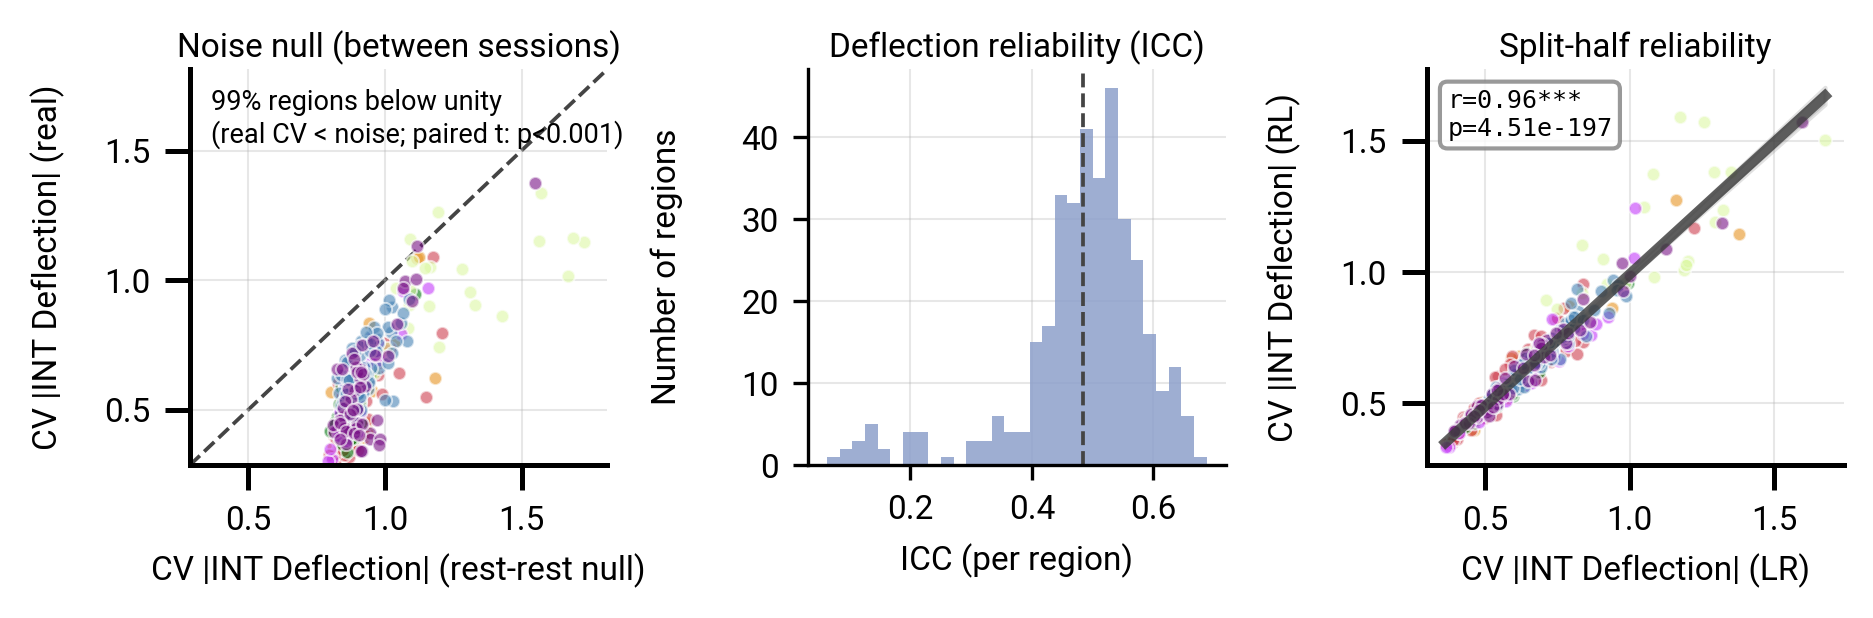

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(6.3, 2.1), dpi=300)

# ── Panel A: between-session rest-rest null vs real CV_deflection ─────────────
_lim = [min(cv_rest_rest.min(), cv_deflection.min()) * 0.95,
        max(cv_rest_rest.max(), cv_deflection.max()) * 1.05]

plot_correlation(cv_rest_rest, cv_deflection, axes[0],
                 data_group=yeo_systems_masked, show_stats=False, fontsize=8,
                 y_label='CV |INT Deflection| (real)',
                 x_label='CV |INT Deflection| (rest-rest null)',
                 size=10, cbar_label='Yeo Systems', show_colorbar=False,
                 data_group_cmap='yeo7', auto_polynomial=False,
                 show_line=False, show_confidence=False)
axes[0].plot(_lim, _lim, color='#444444', lw=0.9, linestyle='--', zorder=0)
axes[0].set_xlim(_lim); axes[0].set_ylim(_lim)
axes[0].set_title('Noise null (between sessions)', fontsize=8, pad=3)
_pct_below = 100.0 - pct_above_null
_p_str = f'p={p_noise:.2e}' if p_noise >= 0.001 else 'p<0.001'
axes[0].text(0.05, 0.95,
             f'{_pct_below:.0f}% regions below unity\n(real CV < noise; paired t: {_p_str})',
             transform=axes[0].transAxes, fontsize=6.5, ha='left', va='top')

# ── Panel B: ICC distribution ─────────────────────────────────────────────────
axes[1].hist(icc_deflection, bins=30, color='#8da0cb', edgecolor='none', alpha=0.85)
axes[1].axvline(np.mean(icc_deflection), color='#444444', lw=0.9, linestyle='--')
axes[1].set_xlabel('ICC (per region)', fontsize=8)
axes[1].set_ylabel('Number of regions', fontsize=8)
axes[1].set_title('Deflection reliability (ICC)', fontsize=8, pad=3)
sns.despine(ax=axes[1], top=True, right=True)
axes[1].grid(True, alpha=0.3, linestyle='-', linewidth=0.5)
axes[1].set_axisbelow(True)

# ── Panel C: split-half reliability (LR vs RL) ───────────────────────────────
plot_correlation(cv_defl_lr, cv_defl_rl, axes[2],
                 data_group=yeo_systems_masked, show_stats=True, fontsize=8, method='pearson',
                 y_label='CV |INT Deflection| (RL)', x_label='CV |INT Deflection| (LR)',
                 size=10, cbar_label='Yeo Systems', show_colorbar=False,
                 data_group_cmap='yeo7', auto_polynomial=False)
axes[2].set_title('Split-half reliability', fontsize=8, pad=3)

for ax in axes.flat:
    ax.yaxis.set_label_coords(-0.3, 0.5)
    ax.tick_params(axis='both', which='major', labelsize=8)

fig.tight_layout()
fig.savefig(os.path.join(nas_scratch_dir, 'suppfig_cv_noise_checks.png'),
            bbox_inches='tight', dpi=1000, transparent=True)
plt.show()


SNR ratio — mean: 1.73, min: 0.96, max: 2.72
Regions with SNR > 1: 99%


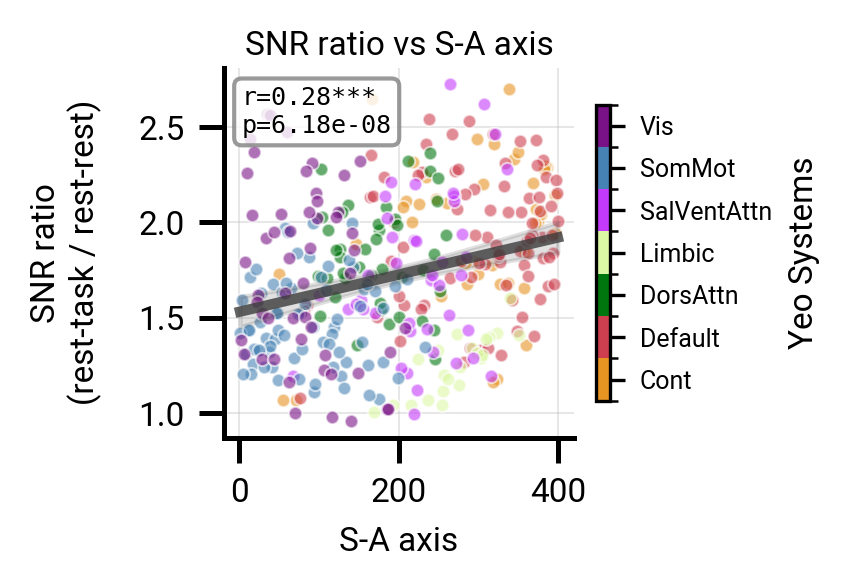

In [27]:
# ── SNR ratio per region: mean rest-task delta / mean rest-rest delta ─────────
mean_rt_defl = (mean_rt_defl_lr + mean_rt_defl_rl) / 2
mean_rr_defl = (mean_rr_defl_lr + mean_rr_defl_rl) / 2
snr_ratio = mean_rt_defl / mean_rr_defl   # (n_regions_masked,)

print(f'SNR ratio — mean: {snr_ratio.mean():.2f}, min: {snr_ratio.min():.2f}, max: {snr_ratio.max():.2f}')
print(f'Regions with SNR > 1: {(snr_ratio > 1).mean()*100:.0f}%')

fig, ax = plt.subplots(1, 1, figsize=(3, 2), dpi=300)

plot_correlation(sa_axis_masked, snr_ratio, ax,
                 data_group=yeo_systems_masked, show_stats=True, fontsize=8, method='pearson',
                 y_label='SNR ratio\n(rest-task / rest-rest)', x_label='S-A axis',
                 size=10, cbar_label='Yeo Systems', show_colorbar=True,
                 data_group_cmap='yeo7', auto_polynomial=False)
ax.set_title('SNR ratio vs S-A axis', fontsize=8, pad=3)
ax.yaxis.set_label_coords(-0.35, 0.5)

fig.tight_layout()
fig.savefig(os.path.join(nas_scratch_dir, 'snr_ratio_sa.png'),
            bbox_inches='tight', dpi=1000, transparent=True)
plt.show()


In [22]:
# REST1LR - WMLR  and  REST1RL - WMRL  deflections (single scans, no averaging)
_rest1lr_m = _data_raw['rfMRIREST1LR'][:, ~region_mask]   # (n_subjects, n_regions)
_rest1rl_m = _data_raw['rfMRIREST1RL'][:, ~region_mask]
_wmlr_m    = _data_raw['tfMRIWMLR'][:, ~region_mask]
_wmrl_m    = _data_raw['tfMRIWMRL'][:, ~region_mask]

defl_lr = np.abs(_wmlr_m - _rest1lr_m)
defl_rl = np.abs(_wmrl_m - _rest1rl_m)

# subject-level (mean over regions) and region-level (mean over subjects)
# for deflection, rest, and task separately
mean_lr_subj = {'Deflection': defl_lr.mean(axis=1),
                'Rest':       _rest1lr_m.mean(axis=1),
                'Task':       _wmlr_m.mean(axis=1)}
mean_rl_subj = {'Deflection': defl_rl.mean(axis=1),
                'Rest':       _rest1rl_m.mean(axis=1),
                'Task':       _wmrl_m.mean(axis=1)}

mean_lr_reg  = {'Deflection': defl_lr.mean(axis=0),
                'Rest':       _rest1lr_m.mean(axis=0),
                'Task':       _wmlr_m.mean(axis=0)}
mean_rl_reg  = {'Deflection': defl_rl.mean(axis=0),
                'Rest':       _rest1rl_m.mean(axis=0),
                'Task':       _wmrl_m.mean(axis=0)}

# Compute all data (subjects × regions lumped together)
all_lr_data = {'Deflection': defl_lr.flatten(),
               'Rest':       _rest1lr_m.flatten(),
               'Task':       _wmlr_m.flatten()}
all_rl_data = {'Deflection': defl_rl.flatten(),
               'Rest':       _rest1rl_m.flatten(),
               'Task':       _wmrl_m.flatten()}

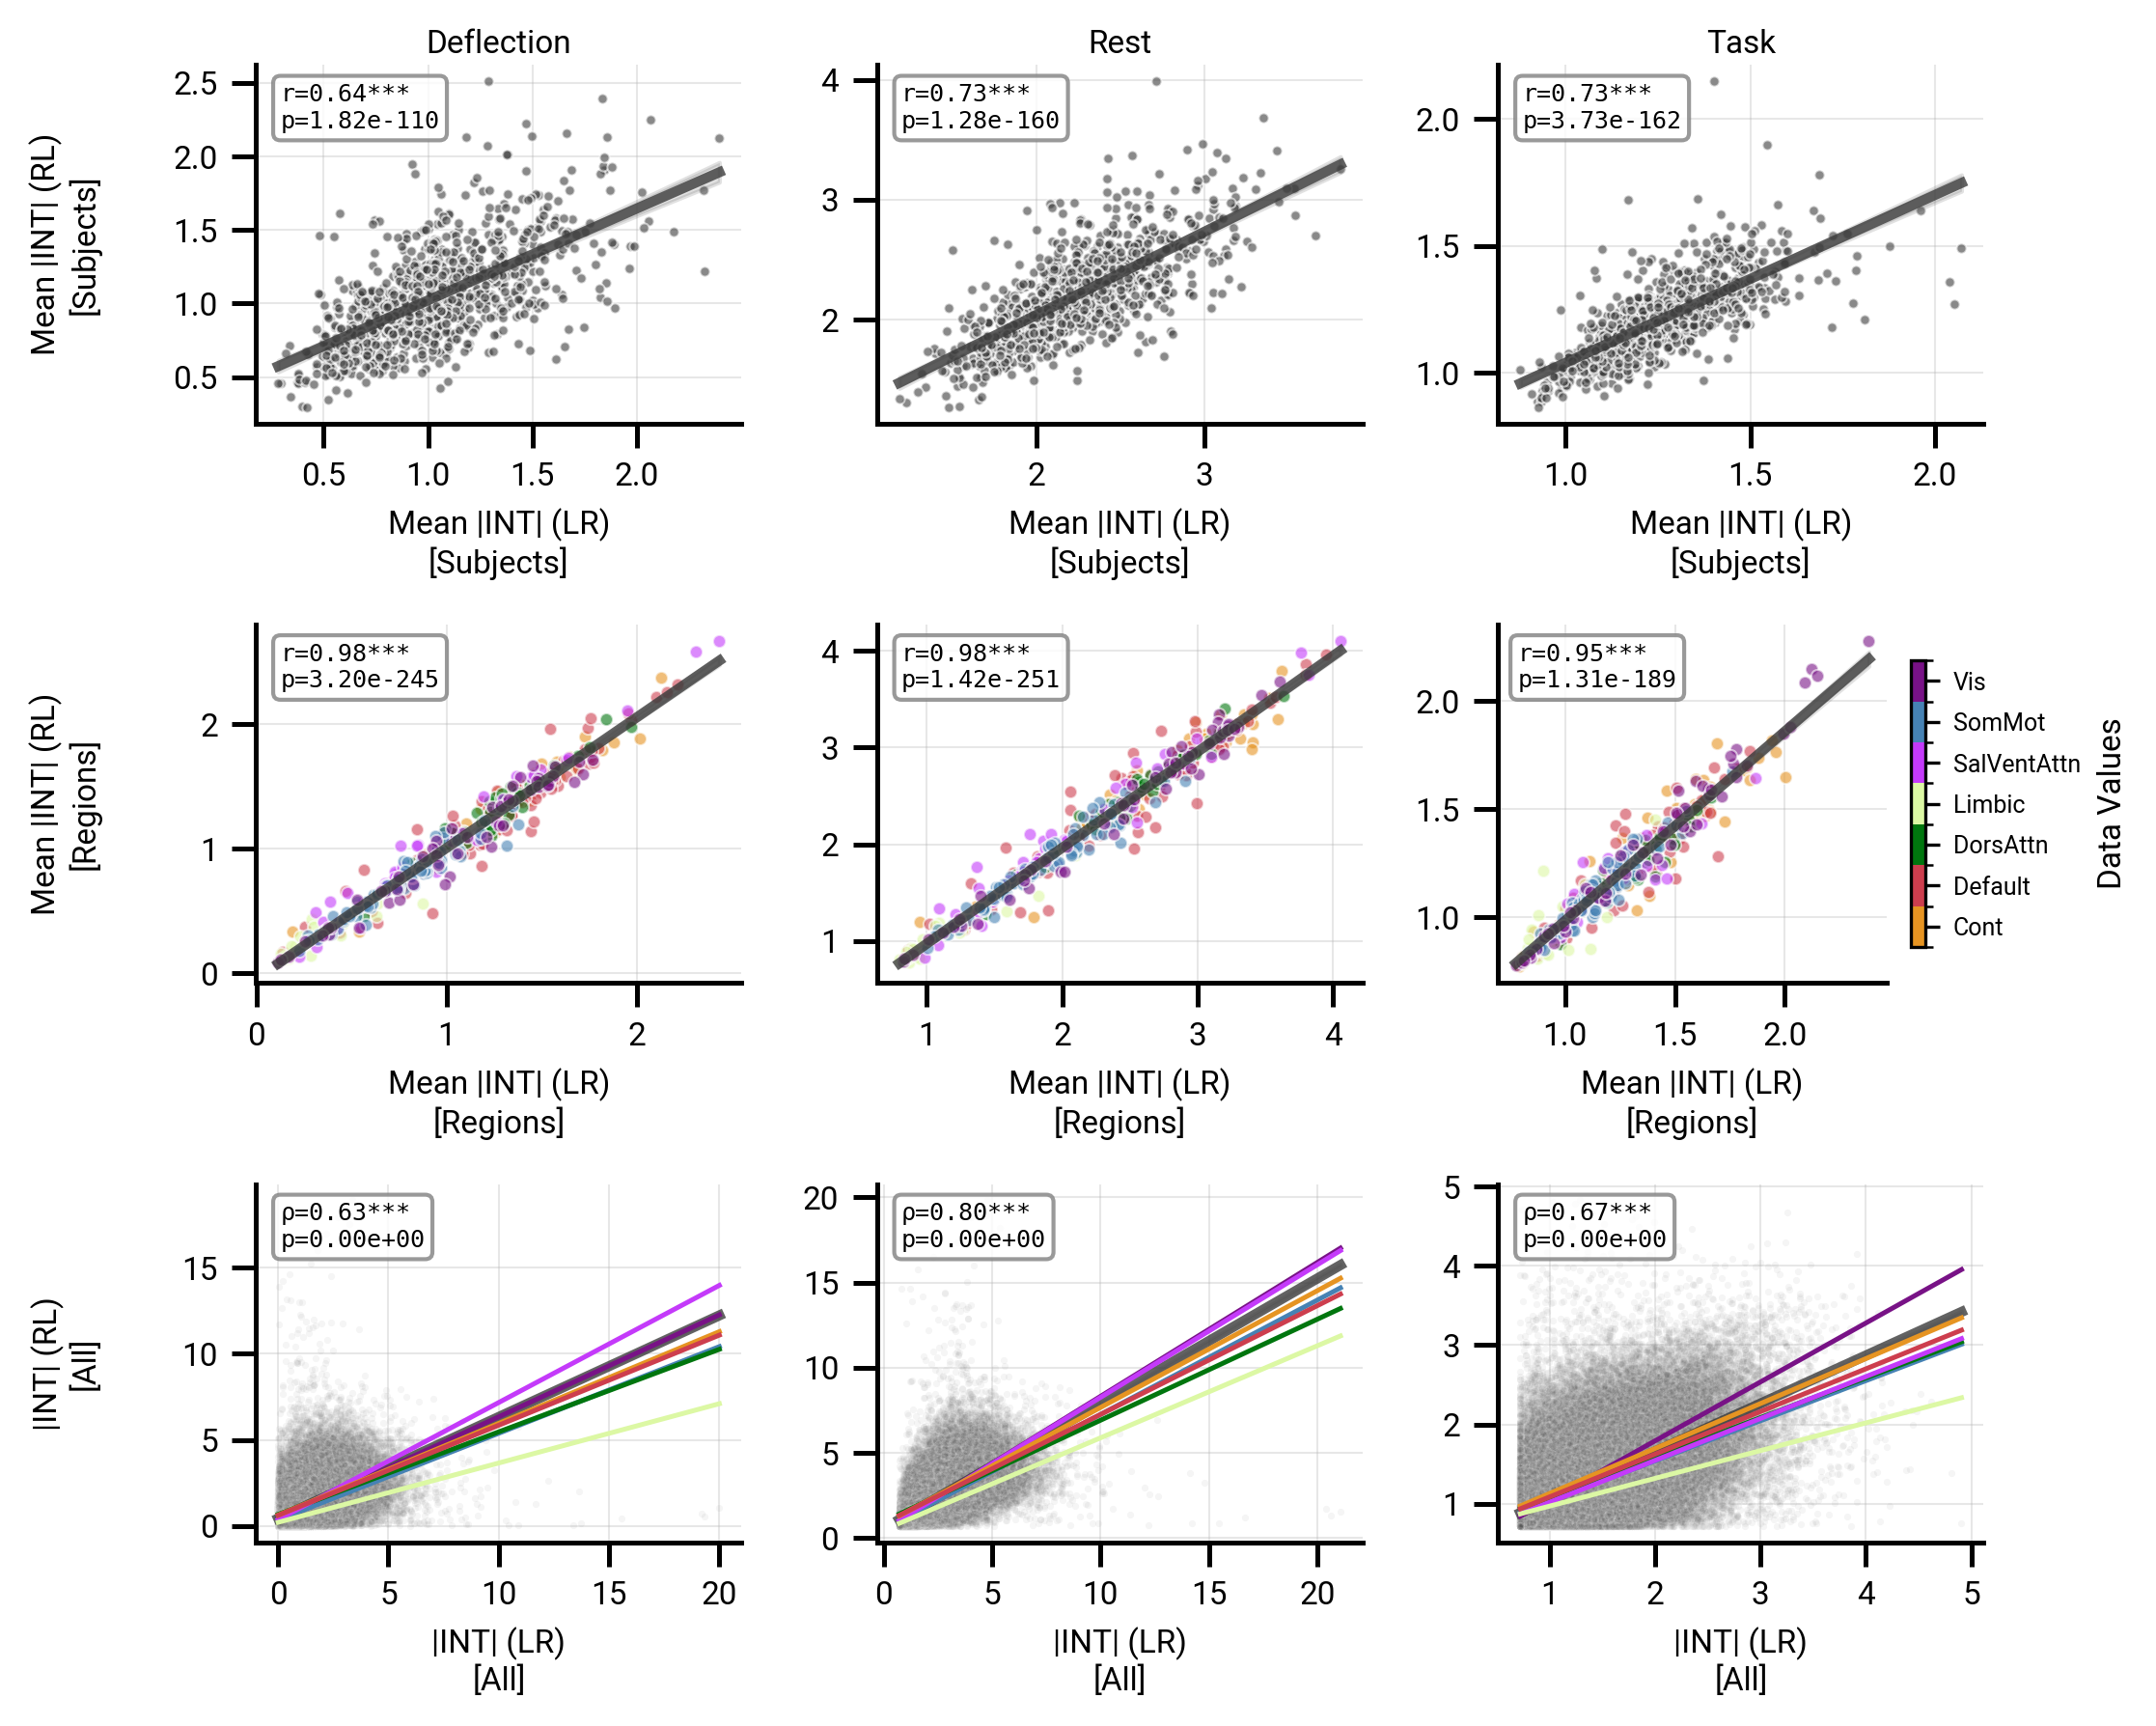

In [23]:
conditions = ['Deflection', 'Rest', 'Task']
fig, axes = plt.subplots(3, 3, figsize=(7.5, 6), dpi=300)

# Tile Yeo labels across subjects for the flattened (subjects × regions) data
yeo_tiled = np.tile(yeo_systems_masked, defl_lr.shape[0])

for col, cond in enumerate(conditions):
    # Row 0: subject-level (mean over regions)
    plot_correlation(mean_lr_subj[cond], mean_rl_subj[cond], axes[0, col],
                     show_stats=True, fontsize=8, method='pearson',
                     y_label='Mean |INT| (RL)\n[Subjects]',
                     x_label='Mean |INT| (LR)\n[Subjects]',
                     size=6, show_colorbar=False, auto_polynomial=False)
    axes[0, col].set_title(cond, fontsize=8, pad=3)

    # Row 1: region-level (mean over subjects)
    if cond == 'Task':
        show_colorbar = True
    else:
        show_colorbar = False
    plot_correlation(mean_lr_reg[cond], mean_rl_reg[cond], axes[1, col],
                     data_group=yeo_systems_masked, show_stats=True, fontsize=8,
                     method='pearson',
                     y_label='Mean |INT| (RL)\n[Regions]',
                     x_label='Mean |INT| (LR)\n[Regions]',
                     size=10, show_colorbar=show_colorbar, data_group_cmap='yeo7',
                     auto_polynomial=False)

    # Row 2: gray scatter + one OLS regression line per Yeo system
    x_all = all_lr_data[cond]
    y_all = all_rl_data[cond]
    valid = np.isfinite(x_all) & np.isfinite(y_all)
    yeo_valid = yeo_tiled[valid]
    x_v, y_v = x_all[valid], y_all[valid]

    plot_correlation(x_v, y_v, axes[2, col],
                     show_stats=True, fontsize=8, method='spearman',
                     y_label='|INT| (RL)\n[All]',
                     x_label='|INT| (LR)\n[All]',
                     size=3, alpha=0.05, show_colorbar=False, auto_polynomial=False)

    x_line = np.linspace(x_v.min(), x_v.max(), 200)
    for system, color in YEO7_COLORS.items():
        mask = yeo_valid == system
        if mask.sum() < 2:
            continue
        m, b = np.polyfit(x_v[mask], y_v[mask], 1)
        axes[2, col].plot(x_line, m * x_line + b, color=color, lw=1.2, zorder=5)

# Clear y labels on non-first columns (plot_correlation defaults empty string to 'Y Variable')
for row in range(3):
    for col in range(1, 3):
        axes[row, col].set_ylabel('')

for ax in axes.flat:
    ax.yaxis.set_label_coords(-0.32, 0.5)
    ax.tick_params(axis='both', which='major', labelsize=8)

fig.tight_layout()
fig.savefig(os.path.join(nas_scratch_dir, 'deflection_reliability_subj_region.png'),
            bbox_inches='tight', dpi=1000, transparent=True)
plt.show()
